# SC4002 Group Assignment — Joint Intent Classification & Slot Filling on MASSIVE (en-US)

Every system in this notebook is a **single joint model** that maps an utterance (`utt`) to
1. one of 60 intent labels, and
2. a set of `[slot type : slot span]` pairs (55 slot types), produced via BIO tagging.

No pretrained models are used (word vectors only, where stated). All parameter counts are printed and asserted ≤ 20M.

## 0. Setup

**What this cell does:** loads the Python libraries we need, fixes the random seed (so every run gives the
same numbers), picks the GPU if one is available, and sets the folder names for the data and saved models.
It also defines the 20M parameter cap that every model is checked against.

In [1]:
import json
import os
import random
import re
import tarfile
import time
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

SEED = 42


def set_seed(seed=SEED):
    # Fix every source of randomness so results are reproducible
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

# Use the GPU if there is one, otherwise fall back to the CPU
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    print('Using GPU:', torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device('cpu')
    print('No GPU found, using CPU')
print('PyTorch version:', torch.__version__)

DATA_DIR = 'data'
DATA_FILE = os.path.join(DATA_DIR, '1.0', 'data', 'en-US.jsonl')
CHECKPOINT_DIR = 'checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

MAX_PARAMS = 20_000_000  # assignment limit for the whole system

Using GPU: NVIDIA GeForce RTX 5060
PyTorch version: 2.11.0+cu128


## 1. Load and verify the dataset (official MASSIVE 1.0 splits)

**What this cell does:** downloads the official MASSIVE 1.0 archive (only if it is not already on disk) and
extracts the English file `en-US.jsonl`. Each line is one example. We group the examples by their existing
`partition` field into **train / dev / test** (no re-splitting), then print and **assert** the required counts
(11,514 / 2,033 / 2,974) so the notebook stops immediately if anything is wrong.

In [2]:
DATASET_URL = 'https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz'

# Download and extract only the English file, and only the first time
if not os.path.exists(DATA_FILE):
    os.makedirs(DATA_DIR, exist_ok=True)
    archive_path = os.path.join(DATA_DIR, 'massive.tar.gz')
    print('Downloading MASSIVE 1.0 ...')
    urllib.request.urlretrieve(DATASET_URL, archive_path)
    with tarfile.open(archive_path) as archive:
        archive.extract('1.0/data/en-US.jsonl', DATA_DIR)

# Each line of the file is one JSON example
records = []
with open(DATA_FILE, encoding='utf-8') as f:
    for line in f:
        records.append(json.loads(line))

# Keep the official split given by the 'partition' field
splits = {'train': [], 'dev': [], 'test': []}
for record in records:
    splits[record['partition']].append(record)

for split_name, examples in splits.items():
    print(f'{split_name:5s}: {len(examples):,} examples')
print('Total:', len(records))

assert len(splits['train']) == 11_514
assert len(splits['dev']) == 2_033
assert len(splits['test']) == 2_974

first = splits['train'][0]
print('\nExample record:')
print('  utt       :', first['utt'])
print('  intent    :', first['intent'])
print('  annot_utt :', first['annot_utt'])

train: 11,514 examples
dev  : 2,033 examples
test : 2,974 examples
Total: 16521

Example record:
  utt       : wake me up at nine am on friday
  intent    : alarm_set
  annot_utt : wake me up at [time : nine am] on [date : friday]


## 2. Preprocessing

`annot_utt` marks slots as `[type : span]`. We parse it into whitespace tokens with BIO tags
(e.g. `B-time I-time`). We verified that the tokens recovered from `annot_utt` are identical to
`utt.split()` for every example, so the model input is exactly `utt` and the labels align 1:1.

Gold slot sets for evaluation are taken directly from this parse as `(slot type, start, end)` spans.

| Word | wake | me | up | at | five | am | this | week |
|---|---|---|---|---|---|---|---|---|
| Tag | O | O | O | O | B-time | I-time | B-date | I-date |

`B-` = beginning of a slot, `I-` = inside (continuing) a slot, `O` = not part of any slot.

**What this cell does:**
* `parse_annotation` turns an annotated sentence into a list of words and a matching list of BIO tags.
* `preprocess` applies it to every example, checks the words match the plain `utt`, and lowercases them.
* Builds the **label lists** (60 intents, 55 slot types → 111 BIO tags) and the **vocabulary**
  (word → ID number) from the **training split only**. Words never seen in training map to `<unk>`.
* Prints how many dev/test words are unknown (OOV rate) and one tagged example.

In [3]:
# Matches one slot in the annotation, e.g. "[time : five am]"
SLOT_PATTERN = re.compile(r'\[(.*?) : (.*?)\]')


def parse_annotation(annot_utt):
    """Split an annotated utterance into words and their BIO tags."""
    words = []
    tags = []
    position = 0  # how far through the string we have read

    for match in SLOT_PATTERN.finditer(annot_utt):
        # Words before this slot are outside any slot
        for word in annot_utt[position:match.start()].split():
            words.append(word)
            tags.append('O')

        # Words inside the slot: first one gets B-, the rest get I-
        slot_type = match.group(1).strip()
        slot_words = match.group(2).split()
        for i, word in enumerate(slot_words):
            words.append(word)
            if i == 0:
                tags.append('B-' + slot_type)
            else:
                tags.append('I-' + slot_type)

        position = match.end()

    # Any words after the last slot
    for word in annot_utt[position:].split():
        words.append(word)
        tags.append('O')

    return words, tags


def preprocess(records):
    examples = []
    for record in records:
        words, tags = parse_annotation(record['annot_utt'])
        # The words from the annotation must line up exactly with the raw utterance
        assert words == record['utt'].split(), f"token mismatch in example {record['id']}"
        examples.append({
            'id': record['id'],
            'tokens': [word.lower() for word in words],
            'tags': tags,
            'intent': record['intent'],
        })
    return examples


data = {}
for split_name in ['train', 'dev', 'test']:
    data[split_name] = preprocess(splits[split_name])

# --- Label lists (built from the training split only) ---
intent_labels = sorted({ex['intent'] for ex in data['train']})

slot_types = set()
for ex in data['train']:
    for tag in ex['tags']:
        if tag != 'O':
            slot_types.add(tag[2:])  # strip the "B-" / "I-" prefix
slot_types = sorted(slot_types)

tag_labels = ['O']
for slot_type in slot_types:
    tag_labels.append('B-' + slot_type)
    tag_labels.append('I-' + slot_type)

intent_to_id = {label: i for i, label in enumerate(intent_labels)}
tag_to_id = {label: i for i, label in enumerate(tag_labels)}

# --- Vocabulary (built from the training split only) ---
PAD = '<pad>'  # fills up short sentences in a batch
UNK = '<unk>'  # stands in for words never seen in training

word_counts = Counter()
for ex in data['train']:
    word_counts.update(ex['tokens'])

vocab = [PAD, UNK] + sorted(word_counts)
word_to_id = {word: i for i, word in enumerate(vocab)}

print(f'{len(intent_labels)} intents, {len(slot_types)} slot types, {len(tag_labels)} BIO tags')
print(f'Vocabulary size: {len(vocab):,}')
assert len(intent_labels) == 60
assert len(slot_types) == 55

# How many dev/test words did the model never see during training?
for split_name in ['dev', 'test']:
    total_words = 0
    unknown_words = 0
    for ex in data[split_name]:
        for word in ex['tokens']:
            total_words += 1
            if word not in word_to_id:
                unknown_words += 1
    print(f'{split_name}: {100 * unknown_words / total_words:.2f}% of words are unknown (OOV)')

example = data['train'][0]
print('\nTagged example:', list(zip(example['tokens'], example['tags'])), '->', example['intent'])

60 intents, 55 slot types, 111 BIO tags
Vocabulary size: 5,304
dev: 3.32% of words are unknown (OOV)
test: 3.51% of words are unknown (OOV)

Tagged example: [('wake', 'O'), ('me', 'O'), ('up', 'O'), ('at', 'O'), ('nine', 'B-time'), ('am', 'I-time'), ('on', 'O'), ('friday', 'B-date')] -> alarm_set


**What this cell does:** packages the data so PyTorch can feed it to the model in batches.
* `MassiveDataset` converts one example into numbers: word IDs, tag IDs and the intent ID.
* `collate_batch` groups several sentences into one batch. Sentences have different lengths, so shorter ones are
  **padded** to the longest; padded positions get tag `-100`, which tells the loss to ignore them.
* `make_loader` creates a batch iterator for a split (shuffled for training, in order for evaluation).

In [4]:
IGNORE_INDEX = -100  # tag value that the loss function skips (used for padding)


class MassiveDataset(Dataset):
    """Turns each example into numbers: word IDs, tag IDs and an intent ID."""

    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        ex = self.examples[index]
        word_ids = [word_to_id.get(word, word_to_id[UNK]) for word in ex['tokens']]
        tag_ids = [tag_to_id[tag] for tag in ex['tags']]
        intent_id = intent_to_id[ex['intent']]
        return word_ids, tag_ids, intent_id


def collate_batch(batch):
    """Pad all sentences in a batch to the same length so they fit in one tensor."""
    batch_size = len(batch)
    lengths = torch.tensor([len(word_ids) for word_ids, _, _ in batch])
    max_len = int(lengths.max())

    words = torch.full((batch_size, max_len), word_to_id[PAD], dtype=torch.long)
    tags = torch.full((batch_size, max_len), IGNORE_INDEX, dtype=torch.long)
    intents = torch.zeros(batch_size, dtype=torch.long)

    for i, (word_ids, tag_ids, intent_id) in enumerate(batch):
        words[i, :len(word_ids)] = torch.tensor(word_ids)
        tags[i, :len(tag_ids)] = torch.tensor(tag_ids)
        intents[i] = intent_id

    return words, lengths, tags, intents


def make_loader(split_name, batch_size, shuffle):
    # A seeded generator makes the shuffling order the same on every run
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(MassiveDataset(data[split_name]), batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate_batch, generator=generator)

## 3. Shared evaluation functions

Used unchanged for every experiment.

* **Intent accuracy** = 100 × correct / N.
* **Slot micro F1**: each prediction is converted to a set of `(slot type, start, end)` spans; a true positive
  needs an exact match of type and span. TP/FP/FN are pooled over all utterances; F1 = 100 × 2TP / (2TP + FP + FN).

Predicted BIO sequences are decoded leniently: an `I-x` tag that does not continue an open `x` span starts a new span.

**What this cell does:**
* `bio_to_spans` turns a tag list back into slots, e.g. `O B-time I-time` → `{(time, 1, 3)}` (word positions 1–2).
* `intent_accuracy` = % of sentences with the right intent.
* `slot_micro_f1` counts correct (TP), extra (FP) and missed (FN) slots across **all** sentences, then computes F1.
* `evaluate_predictions` runs both and also reports the **combined** score = average of the two.
* The checks at the bottom test the scorer itself: feeding it the true answers must give exactly 100 / 100.

In [5]:
def bio_to_spans(tags):
    """Turn a BIO tag list into a set of slots: (slot_type, start, end), end not included."""
    spans = set()
    current_type = None  # type of the slot we are currently inside, if any
    start = None

    # Add a final 'O' so a slot at the very end of the sentence gets closed
    for i, tag in enumerate(list(tags) + ['O']):
        continues_current_slot = tag.startswith('I-') and tag[2:] == current_type
        if continues_current_slot:
            continue

        # Anything else ends the open slot (if there is one) ...
        if current_type is not None:
            spans.add((current_type, start, i))

        # ... and B- or a stray I- starts a new one
        if tag == 'O':
            current_type, start = None, None
        else:
            current_type, start = tag[2:], i

    return spans


def intent_accuracy(gold_intents, predicted_intents):
    correct = 0
    for gold, predicted in zip(gold_intents, predicted_intents):
        if gold == predicted:
            correct += 1
    return 100.0 * correct / len(gold_intents)


def slot_micro_f1(gold_spans, predicted_spans):
    """F1 over exact (type, span) matches, with counts pooled across all sentences."""
    true_pos = 0
    false_pos = 0
    false_neg = 0
    for gold, predicted in zip(gold_spans, predicted_spans):
        true_pos += len(gold & predicted)   # predicted and correct
        false_pos += len(predicted - gold)  # predicted but wrong
        false_neg += len(gold - predicted)  # missed
    if true_pos + false_pos + false_neg == 0:
        return 100.0
    return 100.0 * 2 * true_pos / (2 * true_pos + false_pos + false_neg)


def evaluate_predictions(examples, predicted_intents, predicted_tags):
    gold_intents = [ex['intent'] for ex in examples]
    gold_spans = [bio_to_spans(ex['tags']) for ex in examples]
    predicted_spans = [bio_to_spans(tags) for tags in predicted_tags]

    accuracy = intent_accuracy(gold_intents, predicted_intents)
    f1 = slot_micro_f1(gold_spans, predicted_spans)
    return {'intent_acc': accuracy, 'slot_f1': f1, 'combined': (accuracy + f1) / 2}


# Sanity checks: the scorer should behave exactly as described above
assert bio_to_spans(['O', 'B-time', 'I-time', 'B-date']) == {('time', 1, 3), ('date', 3, 4)}
assert bio_to_spans(['I-time', 'I-date']) == {('time', 0, 1), ('date', 1, 2)}

perfect_intents = [ex['intent'] for ex in data['dev']]
perfect_tags = [ex['tags'] for ex in data['dev']]
perfect_scores = evaluate_predictions(data['dev'], perfect_intents, perfect_tags)
assert perfect_scores == {'intent_acc': 100.0, 'slot_f1': 100.0, 'combined': 100.0}
print('Scorer sanity checks passed.')

Scorer sanity checks passed.


## 4. Shared training / evaluation loop

* Training uses the `train` split only; `dev` is used for model selection; `test` is touched only in the final evaluation.
* Each epoch logs train loss, dev loss, dev intent accuracy, dev slot F1, and elapsed time.
* The checkpoint with the highest dev **combined score** = (intent accuracy + slot micro F1) / 2 is saved.

**What this cell does** (these helpers are reused by every stage):
* `count_params` — counts the model's parameters (total and trainable).
* `predict` — runs the model on a split without learning, and returns its loss, predicted intents and predicted tags.
* `evaluate` — `predict` + the scoring functions above → loss, intent accuracy, slot F1, combined.
* `train_model` — the training loop. For each **epoch** (one full pass over the training data):
  feed batches → measure the joint loss → adjust the weights (Adam optimiser, gradients clipped at 5 to avoid
  unstable jumps) → score on dev → print a log line → save the model if this is the best dev score so far.
* `plot_history` — draws the learning curves (train/dev loss and dev scores per epoch).
* `final_evaluation` — reloads the saved best checkpoint, scores it on dev and test with **no further training**,
  and asserts the dev score matches the one recorded during training.

In [6]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


@torch.no_grad()  # no learning here, so skip gradient tracking
def predict(model, split_name, batch_size=256):
    """Run the model over a whole split. Returns average loss, predicted intents and predicted tags."""
    model.eval()
    total_loss = 0.0
    num_examples = 0
    predicted_intents = []
    predicted_tags = []

    for words, lengths, tags, intents in make_loader(split_name, batch_size, shuffle=False):
        words = words.to(DEVICE)
        tags = tags.to(DEVICE)
        intents = intents.to(DEVICE)

        intent_scores, slot_scores = model(words, lengths)
        loss = model.loss(intent_scores, slot_scores, intents, tags)
        total_loss += loss.item() * len(words)
        num_examples += len(words)

        # Highest-scoring intent for each sentence
        for intent_id in intent_scores.argmax(dim=-1).tolist():
            predicted_intents.append(intent_labels[intent_id])

        # Highest-scoring tag for each word, cut back to the real sentence length
        tag_ids_per_sentence = model.decode_slots(slot_scores, lengths)
        for tag_ids, length in zip(tag_ids_per_sentence, lengths.tolist()):
            predicted_tags.append([tag_labels[t] for t in tag_ids[:length]])

    return total_loss / num_examples, predicted_intents, predicted_tags


def evaluate(model, split_name):
    loss, predicted_intents, predicted_tags = predict(model, split_name)
    scores = evaluate_predictions(data[split_name], predicted_intents, predicted_tags)
    scores['loss'] = loss
    return scores


def train_model(model, name, epochs, lr, batch_size, weight_decay=0.0, clip=5.0):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    checkpoint_path = os.path.join(CHECKPOINT_DIR, f'{name}_best.pt')

    history = []
    best = {'combined': -1}
    training_start = time.time()

    for epoch in range(1, epochs + 1):
        epoch_start = time.time()
        model.train()
        total_loss = 0.0
        num_examples = 0

        for words, lengths, tags, intents in make_loader('train', batch_size, shuffle=True):
            words = words.to(DEVICE)
            tags = tags.to(DEVICE)
            intents = intents.to(DEVICE)

            intent_scores, slot_scores = model(words, lengths)
            loss = model.loss(intent_scores, slot_scores, intents, tags)

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)  # stops very large, unstable updates
            optimizer.step()

            total_loss += loss.item() * len(words)
            num_examples += len(words)

        # Check how the model is doing on the validation (dev) split
        dev = evaluate(model, 'dev')
        epoch_time = time.time() - epoch_start
        total_time = time.time() - training_start

        history.append({
            'epoch': epoch,
            'train_loss': total_loss / num_examples,
            'dev_loss': dev['loss'],
            'dev_intent_acc': dev['intent_acc'],
            'dev_slot_f1': dev['slot_f1'],
            'dev_combined': dev['combined'],
            'epoch_time_s': epoch_time,
            'elapsed_s': total_time,
        })

        # Save the model whenever it beats the best dev score so far
        note = ''
        if dev['combined'] > best['combined']:
            best = {'epoch': epoch, **dev}
            torch.save({'model_state': model.state_dict(), 'epoch': epoch, 'dev_metrics': dev}, checkpoint_path)
            note = '  <- best, saved'

        print(f"epoch {epoch:2d} | train loss {total_loss / num_examples:.4f} | dev loss {dev['loss']:.4f} | "
              f"dev intent acc {dev['intent_acc']:.2f} | dev slot F1 {dev['slot_f1']:.2f} | "
              f"combined {dev['combined']:.2f} | {epoch_time:.1f}s (total {total_time:.1f}s){note}")

    print(f"\nBest checkpoint: epoch {best['epoch']} | dev intent acc {best['intent_acc']:.2f} | "
          f"dev slot F1 {best['slot_f1']:.2f} | dev combined {best['combined']:.2f} | file {checkpoint_path}")
    return history, best, checkpoint_path


def plot_history(history, title):
    epochs = [row['epoch'] for row in history]
    fig, (loss_ax, score_ax) = plt.subplots(1, 2, figsize=(12, 4))

    # Left: loss curves
    loss_ax.plot(epochs, [row['train_loss'] for row in history], 'o-', label='train loss')
    loss_ax.plot(epochs, [row['dev_loss'] for row in history], 'o-', label='dev loss')
    loss_ax.set_xlabel('epoch')
    loss_ax.set_ylabel('joint loss')
    loss_ax.set_title(f'{title}: loss')
    loss_ax.legend()

    # Right: dev scores
    score_ax.plot(epochs, [row['dev_intent_acc'] for row in history], 'o-', label='dev intent acc')
    score_ax.plot(epochs, [row['dev_slot_f1'] for row in history], 'o-', label='dev slot micro F1')
    score_ax.plot(epochs, [row['dev_combined'] for row in history], 'o--', label='dev combined')
    score_ax.set_xlabel('epoch')
    score_ax.set_ylabel('%')
    score_ax.set_title(f'{title}: dev metrics')
    score_ax.legend()

    plt.tight_layout()
    plt.show()


def final_evaluation(model, checkpoint_path, best):
    """Load the saved best model and score it on dev and test, with no further training."""
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    model.to(DEVICE)
    print(f"Loaded {checkpoint_path} (epoch {checkpoint['epoch']})")

    results = {}
    for split_name in ['dev', 'test']:
        scores = evaluate(model, split_name)
        results[split_name] = scores
        print(f"{split_name:5s} | intent accuracy {scores['intent_acc']:.2f}% | "
              f"slot micro F1 {scores['slot_f1']:.2f}% | combined {scores['combined']:.2f}")

    # The reloaded model must reproduce the dev score we saw during training
    assert abs(results['dev']['combined'] - best['combined']) < 1e-6, 'dev score differs from training run'
    print('Reloaded checkpoint reproduces the best validation score.')
    return results

# Stage 1 — Baseline: joint (unidirectional) LSTM tagger + classifier

**Architecture.** Input: lowercased whitespace tokens of `utt` → word ids (vocabulary from the training split, unknown words → `<unk>`).

1. Word embedding (dim 100, randomly initialised, trained from scratch).
2. One shared single-layer **left-to-right LSTM** encoder (hidden 128).
3. **Slot head:** linear layer on each LSTM output → 111 BIO tags (argmax per token).
4. **Intent head:** final LSTM hidden state (after reading the last word) → linear layer → 60 intents.

**Outputs.** One intent label and a BIO sequence per utterance, decoded into `[slot type : span]` pairs.

**Loss.** Joint loss = cross-entropy(intent) + token-level cross-entropy(slots) (padding ignored).

**Optimiser.** Adam, lr 1e-3, batch 32, gradient clipping at 5, 15 epochs, no regularisation / dropout.

**What this cell does:** defines the model class `JointLSTM`.
* `forward` — embeds the words, runs the LSTM over them left-to-right (padding is skipped via "packing"),
  sends every word's output to the slot head, and the LSTM's memory after the last word to the intent head.
* `loss` — intent loss + slot loss, so one update improves both tasks together.
* `decode_slots` — picks the highest-scoring tag for each word.

It then creates the baseline model, prints its structure and parameter count, and asserts it is ≤ 20M.

In [7]:
class JointLSTM(nn.Module):
    def __init__(self, vocab_size, num_intents, num_tags, embedding_dim=100, hidden_size=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_size, batch_first=True)  # reads left-to-right only
        self.slot_head = nn.Linear(hidden_size, num_tags)       # one tag per word
        self.intent_head = nn.Linear(hidden_size, num_intents)  # one intent per sentence
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

    def forward(self, words, lengths):
        embedded = self.embedding(words)

        # "Packing" lets the LSTM skip the padding at the end of short sentences
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths.cpu(), batch_first=True,
                                                   enforce_sorted=False)
        packed_outputs, (final_hidden, _) = self.lstm(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(packed_outputs, batch_first=True,
                                                      total_length=words.size(1))

        slot_scores = self.slot_head(outputs)  # every word's output -> its tag
        sentence_summary = final_hidden[-1]    # LSTM memory after the last real word
        intent_scores = self.intent_head(sentence_summary)
        return intent_scores, slot_scores

    def loss(self, intent_scores, slot_scores, intents, tags):
        intent_loss = self.loss_fn(intent_scores, intents)
        # Flatten (batch, words, tags) -> (batch * words, tags) so every word is scored
        slot_loss = self.loss_fn(slot_scores.reshape(-1, slot_scores.size(-1)), tags.reshape(-1))
        return intent_loss + slot_loss

    def decode_slots(self, slot_scores, lengths):
        # Simply pick the highest-scoring tag for each word
        return slot_scores.argmax(dim=-1).tolist()


set_seed()
baseline = JointLSTM(len(vocab), len(intent_labels), len(tag_labels))
print(baseline)

total_params, trainable_params = count_params(baseline)
print(f'Total parameters: {total_params:,} | trainable: {trainable_params:,}')
assert total_params <= MAX_PARAMS, 'model exceeds the 20M parameter cap'

JointLSTM(
  (embedding): Embedding(5304, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (slot_head): Linear(in_features=128, out_features=111, bias=True)
  (intent_head): Linear(in_features=128, out_features=60, bias=True)
  (loss_fn): CrossEntropyLoss()
)
Total parameters: 670,219 | trainable: 670,219


### Stage 1 — training and checkpoint selection (train split only, selection on dev)

**What this cell does:** trains the baseline for 15 epochs on the training split. Each log line shows the
train loss, dev loss, dev intent accuracy, dev slot F1, combined score and time taken. Whenever the dev
combined score beats the best so far, the model is saved (`<- best, saved`). The final line reports the
best epoch, its dev scores and the checkpoint filename.

In [8]:
set_seed()
BASELINE_EPOCHS = 15

baseline_history, baseline_best, baseline_checkpoint = train_model(
    baseline,
    name='stage1_baseline',
    epochs=BASELINE_EPOCHS,
    lr=1e-3,
    batch_size=32,
)

epoch  1 | train loss 4.6934 | dev loss 3.2284 | dev intent acc 47.86 | dev slot F1 18.62 | combined 33.24 | 3.1s (total 3.1s)  <- best, saved


epoch  2 | train loss 2.5651 | dev loss 2.1575 | dev intent acc 66.70 | dev slot F1 33.60 | combined 50.15 | 2.7s (total 5.8s)  <- best, saved


epoch  3 | train loss 1.7627 | dev loss 1.7326 | dev intent acc 73.14 | dev slot F1 41.79 | combined 57.47 | 2.8s (total 8.6s)  <- best, saved


epoch  4 | train loss 1.3356 | dev loss 1.5136 | dev intent acc 76.93 | dev slot F1 47.57 | combined 62.25 | 2.7s (total 11.4s)  <- best, saved


epoch  5 | train loss 1.0556 | dev loss 1.4061 | dev intent acc 77.42 | dev slot F1 52.46 | combined 64.94 | 2.7s (total 14.1s)  <- best, saved


...

epoch 11 | train loss 0.3358 | dev loss 1.2683 | dev intent acc 79.34 | dev slot F1 62.23 | combined 70.79 | 2.7s (total 30.4s)  <- best, saved


epoch 12 | train loss 0.2843 | dev loss 1.2728 | dev intent acc 79.05 | dev slot F1 62.60 | combined 70.83 | 2.7s (total 33.1s)  <- best, saved


epoch 13 | train loss 0.2420 | dev loss 1.2854 | dev intent acc 79.59 | dev slot F1 62.89 | combined 71.24 | 2.7s (total 35.8s)  <- best, saved


epoch 14 | train loss 0.2101 | dev loss 1.2960 | dev intent acc 79.39 | dev slot F1 63.50 | combined 71.45 | 2.7s (total 38.5s)  <- best, saved


epoch 15 | train loss 0.1762 | dev loss 1.3156 | dev intent acc 79.19 | dev slot F1 63.26 | combined 71.23 | 2.7s (total 41.2s)

Best checkpoint: epoch 14 | dev intent acc 79.39 | dev slot F1 63.50 | dev combined 71.45 | file checkpoints\stage1_baseline_best.pt


**What this cell does:** plots the learning curves. Left: training vs dev loss per epoch — when dev loss
starts rising while training loss keeps falling, the model is starting to overfit (memorise). Right: dev
intent accuracy, slot F1 and combined score per epoch.

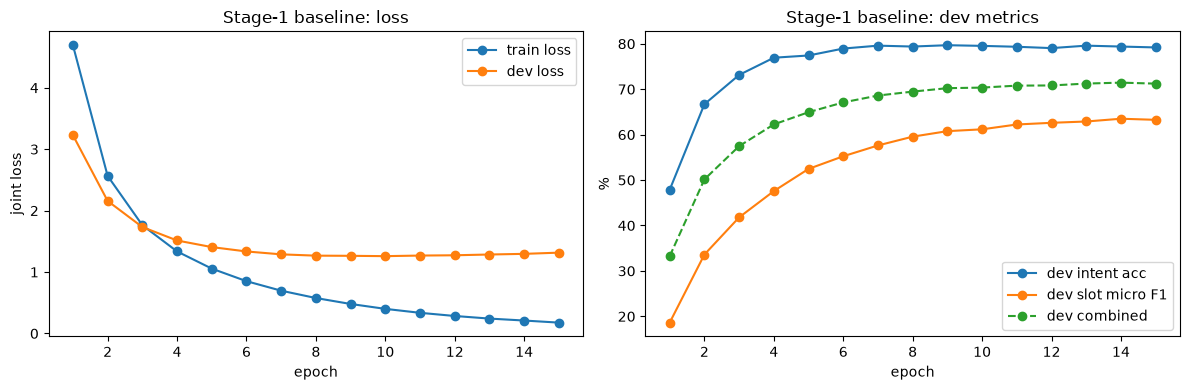

In [9]:
plot_history(baseline_history, 'Stage-1 baseline')

### Stage 1 — final evaluation of the saved checkpoint (no further training)

**What this cell does:** builds a fresh copy of the model, loads the saved best checkpoint into it, and
scores it on dev and test. The dev score must equal the best dev score from training (checked by an
assert), proving the result is reproducible. The **test** scores printed here are the official Stage 1 results.

In [10]:
baseline_for_eval = JointLSTM(len(vocab), len(intent_labels), len(tag_labels))
baseline_results = final_evaluation(baseline_for_eval, baseline_checkpoint, baseline_best)

Loaded checkpoints\stage1_baseline_best.pt (epoch 14)
dev   | intent accuracy 79.39% | slot micro F1 63.50% | combined 71.45
test  | intent accuracy 78.68% | slot micro F1 57.87% | combined 68.28
Reloaded checkpoint reproduces the best validation score.
